# 🚀 Class 1: The ML Pipeline & Making Sense of Text

Welcome to the Applied Machine Learning Autumn Session!

### Today's Agenda:
**Part 1: The ML Problem-Solving Framework**
* What is ML? (Supervised vs. Unsupervised)
* Data Management: Splitting data (Train/Test), handling missing values, and the concept of features.

**Part 2: Text Data & Feature Engineering**
* How do machines read? (Tokenization, Bag of Words, TF-IDF).
* Hands-on: Spam vs. Ham (SMS) classification using Scikit-Learn.
* Model: Naive Bayes.

**Part 3: Evaluation Techniques**
* Beyond just "Accuracy": Precision, Recall, F1-Score, and the Confusion Matrix.
* Hands-on: Evaluating the text model and visualizing where the machine gets confused.

💡 *Rule #1 of this class: Learn by doing. Experiment with the code, change the texts, and see what happens!*

In [235]:
# Let's import the necessary tools for today's class
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn tools
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# Set visualization style
sns.set_theme(style="whitegrid")
print("Libraries loaded successfully! 🚀")

Libraries loaded successfully! 🚀


---
## Part 1: The ML Problem-Solving Framework 🧠

### What is Machine Learning?
Machine Learning is teaching a computer to recognize patterns by showing it data, rather than giving it explicit rules (like `if/else` statements).

* **Supervised Learning:** The data has labels (e.g., teaching a computer to recognize Spam vs Ham by showing it thousands of examples labeled "Spam" or "Ham").
* **Unsupervised Learning:** The data has NO labels (e.g., giving a computer a list of customer purchases and asking it to group similar customers together).

### Data Management: Features, Missing Values, and Splitting
Before feeding data to an algorithm, an ML Engineer must prepare it.
1. **Features (X) & Target (y):** Features are the inputs (e.g., a text message). The Target is what we want to predict (e.g., Spam or Ham).
2. **Handling Missing Values:** Real-world data is messy. Sometimes data is missing (NaN). We must either delete these rows or fill them in.
3. **Train/Test Split:** We never test the model on the data it learned from! We split the data into a **Training Set** (to study) and a **Testing Set** (for the final exam).

In [236]:
# --- MINI DEMO: Handling Missing Values & Splitting Data ---

# 1. Create a messy dummy dataset
dummy_data = pd.DataFrame({
    'Age': [25, 30, np.nan, 22, 35],
    'Salary': [50000, 60000, 55000, np.nan, 70000],
    'Bought_Product': [1, 0, 1, 0, 1]  # Target (y)
})

print("MESSY DATA:")
print(dummy_data)

# 2. Handle Missing Values (Fill empty Age with average age, fill Salary with 0)
dummy_data['Age'] = dummy_data['Age'].fillna(dummy_data['Age'].mean())
dummy_data['Salary'] = dummy_data['Salary'].fillna(0)

print("\nCLEANED DATA:")
print(dummy_data)

# 3. Split into Features (X) and Target (y)
X_dummy = dummy_data[['Age', 'Salary']]
y_dummy = dummy_data['Bought_Product']

# 4. Train/Test Split (80% Train, 20% Test)
X_train_dummy, X_test_dummy, y_train_dummy, y_test_dummy = train_test_split(X_dummy, y_dummy, test_size=0.2, random_state=42)
print(f"\nData Splitting: {len(X_train_dummy)} rows for training, {len(X_test_dummy)} rows for testing.")

MESSY DATA:
    Age   Salary  Bought_Product
0  25.0  50000.0               1
1  30.0  60000.0               0
2   NaN  55000.0               1
3  22.0      NaN               0
4  35.0  70000.0               1

CLEANED DATA:
    Age   Salary  Bought_Product
0  25.0  50000.0               1
1  30.0  60000.0               0
2  28.0  55000.0               1
3  22.0      0.0               0
4  35.0  70000.0               1

Data Splitting: 4 rows for training, 1 rows for testing.


---
## Part 2: Text Data & Feature Engineering 📖🤖

Machine Learning models are math equations. They **cannot** read letters or words (like "Hello"). They only understand **numbers**.

### How do machines read?
1. **Tokenization:** Breaking a sentence down into individual words (tokens).
2. **Bag of Words (BoW):** Counting how many times each word appears in a sentence.
3. **TF-IDF (Term Frequency - Inverse Document Frequency):** A smarter counting method that punishes very common words (like "the", "is") and highlights unique, meaningful words.

In [237]:
# Let's see Bag of Words in action!
texts = [
    "I love machine learning",
    "I love coding in Python",
    "Machine learning is fun"
]

# Create the Vectorizer (The text-to-number converter)
vectorizer = CountVectorizer()
text_numbers = vectorizer.fit_transform(texts)

print("Vocabulary the machine learned (Tokens):")
print(vectorizer.get_feature_names_out())

print("\nText converted to numbers (Matrix):")
print(text_numbers.toarray())

Vocabulary the machine learned (Tokens):
['coding' 'fun' 'in' 'is' 'learning' 'love' 'machine' 'python']

Text converted to numbers (Matrix):
[[0 0 0 0 1 1 1 0]
 [1 0 1 0 0 1 0 1]
 [0 1 0 1 1 0 1 0]]


### But wait, what is TF-IDF? 🤔
In the **Bag of Words** example above, words are just counted. But what if a word like "the", "is", or "and" appears 100 times? The machine might mathematically think it is the most important word in the sentence!

**TF-IDF (Term Frequency - Inverse Document Frequency)** fixes this by scoring words instead of just counting them:
* **TF (Term Frequency):** How often does the word appear in *this specific* sentence? (More appearances = higher score).
* **IDF (Inverse Document Frequency):** How often does the word appear in *ALL* sentences? (If it appears everywhere, it is probably a boring word like "the". More appearances = lower score!).

Let's look at a simple example to see how it punishes common words.

In [238]:
# A tiny dataset with very common words ('the', 'is') and unique words ('barking', 'meowing')
toy_texts = [
    "the dog is barking",
    "the cat is meowing",
    "the dog and the cat"
]

# Create the TF-IDF Vectorizer
tfidf_toy = TfidfVectorizer()

# Learn the vocabulary and convert sentences to TF-IDF scores
tfidf_numbers = tfidf_toy.fit_transform(toy_texts)

# Let's put it in a Pandas DataFrame so it is easy to read!
tfidf_df = pd.DataFrame(tfidf_numbers.toarray(), columns=tfidf_toy.get_feature_names_out())

print("TF-IDF Scores:")
display(tfidf_df)

print("\nNotice the scores:")
print("- The unique words ('barking', 'meowing') get HIGH scores (0.63).")
print("- The common word ('the') gets a LOW score (0.32 or 0.50), even though it appears constantly!")

TF-IDF Scores:


,and,barking,cat,dog,is,meowing,the
0,0.000000,0.631745,0.000000,0.480458,0.480458,0.000000,0.373119
1,0.000000,0.000000,0.480458,0.000000,0.480458,0.631745,0.373119
2,0.530587,0.000000,0.403525,0.403525,0.000000,0.000000,0.626747



Notice the scores:
- The unique words ('barking', 'meowing') get HIGH scores (0.63).
- The common word ('the') gets a LOW score (0.32 or 0.50), even though it appears constantly!


### Hands-on: Spam vs. Ham (SMS) Classification 📩
Let's load a real-world dataset of SMS text messages. We will extract features using **TF-IDF** and train a **Naive Bayes** model.

Here is what our data looks like:


,label,message,label_num
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


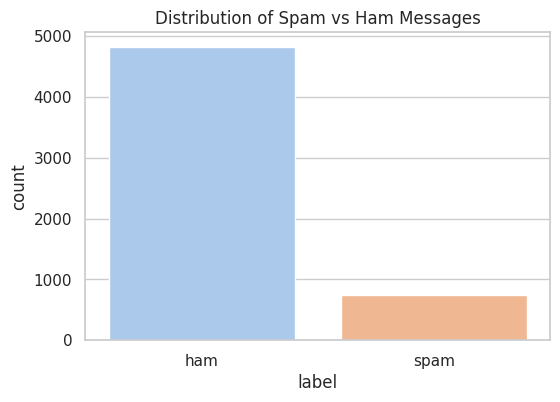

Notice the Class Imbalance! Most of our data is 'ham'.


In [239]:
# Load the dataset
url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"
df = pd.read_csv(url, sep='\t', names=['label', 'message'])

# Convert Labels to Numbers (Ham = 0, Spam = 1)
df['label_num'] = df['label'].map({'ham': 0, 'spam': 1})

# Show the first 5 rows of the dataset
print("Here is what our data looks like:")
display(df.head())

# Visualize the data
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='label', hue='label', palette='pastel', legend=False)
plt.title("Distribution of Spam vs Ham Messages")
plt.show()

print("Notice the Class Imbalance! Most of our data is 'ham'.")

In [240]:
# Step 1: Split into Train and Test
X = df['message']
y = df['label_num']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 2: Feature Engineering using TF-IDF
tfidf = TfidfVectorizer(stop_words='english')

# FIT (learn vocabulary) and TRANSFORM (convert to numbers) the Training data
X_train_transformed = tfidf.fit_transform(X_train)

# ONLY TRANSFORM the Test data (no peeking at the exam!)
X_test_transformed = tfidf.transform(X_test)

print(f"Training data shape: {X_train_transformed.shape} (Rows, Unique Words)")

Training data shape: (4457, 7441) (Rows, Unique Words)


In [241]:
# Step 3: Model Training
# We use Naive Bayes, which calculates probabilities based on word frequencies.
model = MultinomialNB()

model.fit(X_train_transformed, y_train)
print("Model training complete! 🎉")

Model training complete! 🎉


---
## 🧠 Mini Activity: Test Your Own Texts!

Run the cell below, and change the text in `my_messages` to see if you can trick the AI!
Can you write a text that sounds like spam but isn't? Or vice versa?

In [242]:
def test_my_messages(message_list):
    # 1. Transform the new text into numbers using the TF-IDF we trained earlier
    numbers = tfidf.transform(message_list)

    # 2. Make the prediction (0 or 1)
    preds = model.predict(numbers)

    # 3. Get the probabilities (How confident is the model?)
    probs = model.predict_proba(numbers)

    for msg, pred, prob in zip(message_list, preds, probs):
        label = "🚨 SPAM" if pred == 1 else "✅ HAM"
        confidence = prob[pred] * 100
        print(f"Message: '{msg}'")
        print(f"Prediction: {label} (Confidence: {confidence:.2f}%)\n")

# Try changing these strings!
my_messages = [
    "Hey bro, are we still meeting for pizza tonight at 8?",
    "CONGRATULATIONS! You have won a $1000 Walmart Gift Card. Click here to claim your prize now!",
    "Urgent! Please call customer service immediately regarding your recent bank transaction."
]

test_my_messages(my_messages)

Message: 'Hey bro, are we still meeting for pizza tonight at 8?'
Prediction: ✅ HAM (Confidence: 99.46%)

Message: 'CONGRATULATIONS! You have won a $1000 Walmart Gift Card. Click here to claim your prize now!'
Prediction: 🚨 SPAM (Confidence: 87.65%)

Message: 'Urgent! Please call customer service immediately regarding your recent bank transaction.'
Prediction: 🚨 SPAM (Confidence: 56.55%)



---
## Part 3: Evaluation Techniques 📊

### Beyond just "Accuracy"
If 90% of our dataset is "Ham", a model that simply guesses "Ham" every single time will be 90% accurate. But it will never catch a single spam message! Therefore, accuracy is not enough.

Instead, we look at:
* **Precision:** Quality. When the model says "SPAM", how often is it actually right? (High precision means we don't accidentally send important texts from mom to the junk folder).
* **Recall:** Quantity. Out of all the ACTUAL SPAM in the world, what percentage did our model successfully catch?
* **F1-Score:** The perfect balance between Precision and Recall.

### Making Sense of the Metrics 📏
Now that we know our TP, TN, FP, and FN, how do we actually grade our AI?
- **True Positives (TP):** Spam correctly caught.
- **True Negatives (TN):** Ham correctly left alone.
- **False Positives (FP):** Ham mistakenly labeled as Spam (Dangerous!).
- **False Negatives (FN):** Spam mistakenly labeled as Ham (Annoying).

* **1. Accuracy (The Overall Score)**
  * **Math:** $\frac{TP + TN}{Total}$
  * **Meaning:** "Out of all messages, how many did we guess correctly?"
  * **The Trap:** If 90% of our emails are Ham, a lazy AI that just guesses "Ham" every single time gets a 90% Accuracy, even though it caught 0 Spam! This is why we need the next three metrics.

* **2. Precision (The "Trust" Metric)**
  * **Math:** $\frac{TP}{TP + FP}$
  * **Meaning:** "When the AI claims a message is SPAM, how often is it actually correct?"
  * **Real-World Impact:** If Precision is low, the AI is throwing real, important messages from your boss or family into the Junk folder (High False Positives). We want Precision to be near 100%!

* **3. Recall (The "Catcher" Metric)**
  * **Math:** $\frac{TP}{TP + FN}$
  * **Meaning:** "Out of ALL the actual SPAM in the world, what percentage did our AI successfully catch?"
  * **Real-World Impact:** If Recall is low, the AI is letting lots of Spam sneak into your main inbox (High False Negatives).

* **4. F1-Score (The Perfect Balance)**
  * **Math:** $2 \times \frac{Precision \times Recall}{Precision + Recall}$
  * **Meaning:** In Machine Learning, there is usually a tug-of-war. If you make the AI very strict to protect your inbox (High Precision), it might miss some spam (Low Recall). The F1-Score combines both into a single number to tell you if your model has a healthy balance.

In [243]:
# Make predictions on our Test set
predictions = model.predict(X_test_transformed)

acc = accuracy_score(y_test, predictions)
print(f"Simple Accuracy: {acc * 100:.2f}%\n")

# Let's look at the detailed metrics
print("--- Detailed Classification Report ---")
print(classification_report(y_test, predictions, target_names=['Ham', 'Spam']))

Simple Accuracy: 97.85%

--- Detailed Classification Report ---
              precision    recall  f1-score   support

         Ham       0.98      1.00      0.99       966
        Spam       1.00      0.84      0.91       149

    accuracy                           0.98      1115
   macro avg       0.99      0.92      0.95      1115
weighted avg       0.98      0.98      0.98      1115



### Visualizing the Confusion Matrix
A confusion matrix shows exactly where the machine gets confused.


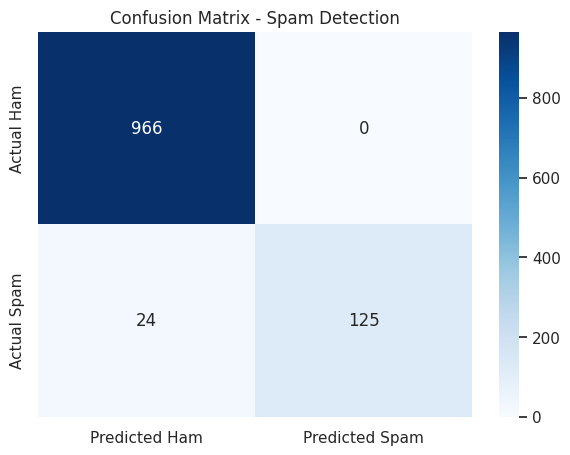

Look at the Top-Right corner. Did the model accidentally classify any real texts as Spam?
Look at the Bottom-Left corner. How many Spams snuck through?


In [244]:
cm = confusion_matrix(y_test, predictions)

plt.figure(figsize=(7,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted Ham', 'Predicted Spam'],
            yticklabels=['Actual Ham', 'Actual Spam'])
plt.title("Confusion Matrix - Spam Detection")
plt.show()

print("Look at the Top-Right corner. Did the model accidentally classify any real texts as Spam?")
print("Look at the Bottom-Left corner. How many Spams snuck through?")

### Swapping the "Brain" of our AI 🧠🔄

**Multinomial Naive Bayes** works like a probability detective, looking at word frequencies.
But what if we want to try a different algorithm?

Let's try **Logistic Regression**. Instead of calculating probabilities word-by-word, Logistic Regression tries to draw a mathematical "line" separating the Spam messages from the Ham messages.

In Scikit-Learn, swapping the AI model takes exactly **one line of code**!

In [245]:
from sklearn.linear_model import LogisticRegression

# 1. Create the new model
lr_model = LogisticRegression()

# 2. Train it on the exact same data
lr_model.fit(X_train_transformed, y_train)

# 3. Make predictions and evaluate
lr_preds = lr_model.predict(X_test_transformed)

print("Logistic Regression Accuracy:", accuracy_score(y_test, lr_preds) * 100, "%")
print("\nClassification Report:")
print(classification_report(y_test, lr_preds, target_names=['Ham', 'Spam']))

Logistic Regression Accuracy: 96.95067264573991 %

Classification Report:
              precision    recall  f1-score   support

         Ham       0.97      1.00      0.98       966
        Spam       1.00      0.77      0.87       149

    accuracy                           0.97      1115
   macro avg       0.98      0.89      0.93      1115
weighted avg       0.97      0.97      0.97      1115



## ✅ Wrapping Up Class 1

Today you successfully:
1. Learned the ML Framework (Data -> Splitting -> Engineering -> Modeling -> Evaluation).
2. Transformed text into mathematical matrices using Tokenization, Bag of Words, and TF-IDF.
3. Trained a Machine Learning model (Naive Bayes) to detect spam.
4. Looked past accuracy and evaluated the model using Precision, Recall, and Confusion Matrices.

**Next Class:** We will leave text behind and enter the world of **Computer Vision** 📷 to detect images and videos!

# 📈 Linear Regression – Learn by Doing

### Today you will:
- Understand what regression is
- Predict real-world values using Python


In [246]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

In [247]:
# Creating a simple dataset
# Study Hours vs Exam Score

data = {
    "Hours_Studied": [1, 2, 3, 4, 5, 6, 7, 8],
    "Exam_Score":   [35, 40, 50, 55, 65, 70, 78, 85]
}

df = pd.DataFrame(data)
df


,Hours_Studied,Exam_Score
0,1,35
1,2,40
2,3,50
3,4,55
4,5,65
5,6,70
6,7,78
7,8,85


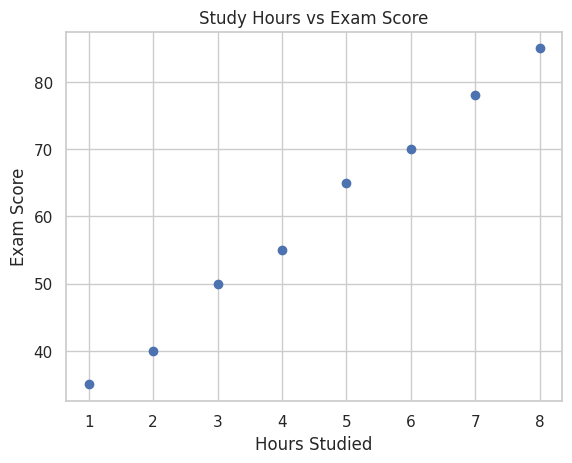

In [248]:
# Visualizing the data
plt.scatter(df["Hours_Studied"], df["Exam_Score"])
plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.title("Study Hours vs Exam Score")
plt.show()

In [249]:
# Input (X) and Output (y)
X = df[["Hours_Studied"]]   # input must be 2D
y = df["Exam_Score"]        # output

In [250]:
# Create and train the model
model = LinearRegression()
model.fit(X, y)

LinearRegression()

In [251]:
m = model.coef_[0]
c = model.intercept_

print(f"m = {m:.2f}")
print(f"c = {c:.2f}")

m = 7.26
c = 27.07


In [252]:
# Predict exam score for a new student
hours = 9
new_data = pd.DataFrame({"Hours_Studied": [hours]})
predicted_score = model.predict(new_data)

print(f"If a student studies {hours} hours, predicted score is {predicted_score[0]:.2f}")

If a student studies 9 hours, predicted score is 92.43


In [253]:
# Model evaluation
predictions = model.predict(X)
error = mean_absolute_error(y, predictions)

print("Mean Absolute Error:", error)

Mean Absolute Error: 0.8809523809523823


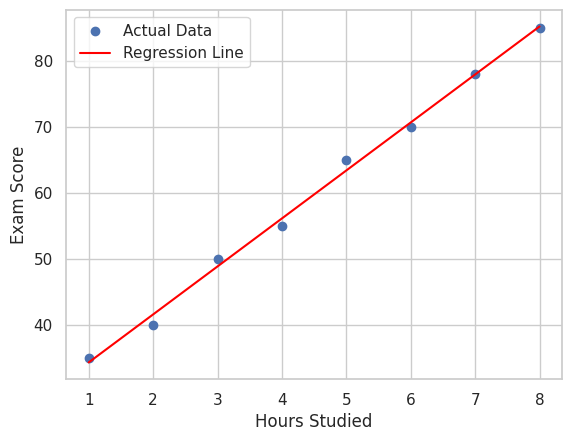

In [254]:
plt.scatter(X, y, label="Actual Data")

plt.plot(X, model.predict(X), color="red", label="Regression Line")

plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")

plt.legend()
plt.show()

## 🧠 Mini Activity

Try this:
1. Change the dataset values
2. Add a new data point
3. Retrain the model
4. Observe how predictions change

💡 This is how real ML experimentation works.

In [255]:
# Experience vs Salary dataset

data2 = {
    "Years_Experience": [0, 1, 2, 3, 4, 5],
    "Salary_LPA":       [3, 4, 5.5, 7, 8.5, 10]
}

df2 = pd.DataFrame(data2)

X2 = df2[["Years_Experience"]]
y2 = df2["Salary_LPA"]

model2 = LinearRegression()
model2.fit(X2, y2)
years = 9

new_data = pd.DataFrame({"Years_Experience": [years]})

predicted_salary = model2.predict(new_data)
print(f"If an emplyee has {years} years of experience, predicted salary is {predicted_salary[0]:.2f}")

If an emplyee has 9 years of experience, predicted salary is 15.62


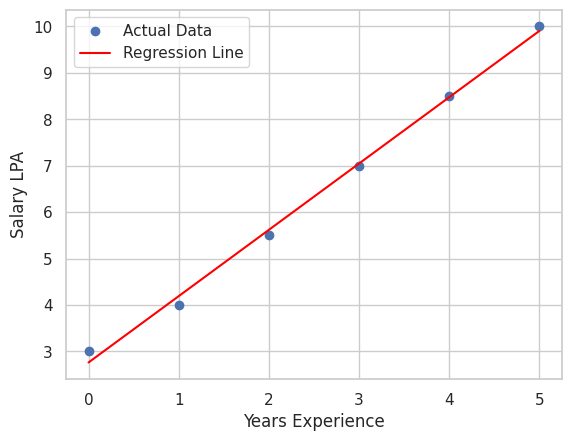

In [256]:
plt.scatter(X2, y2, label="Actual Data")

plt.plot(X2, model2.predict(X2), color="red", label="Regression Line")

plt.xlabel("Years Experience")
plt.ylabel("Salary LPA")

plt.legend()
plt.show()

---
## 🏡 Real-World Project: California House Price Prediction

Now let's use a real dataset! We will use the **California Housing Dataset**.
Our goal is to see if we can predict the value of a house based on the **Median Income** of the neighborhood.

*Note: In this dataset, Income is measured in tens of thousands (e.g., 5 = \$50,000) and House Value is measured in hundreds of thousands (e.g., 2 = \$200,000).*

In [257]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split

# 1. Load the real-world dataset
california = fetch_california_housing(as_frame=True)
df_housing = california.frame

# 2. To make our plot easy to read, let's take a random sample of 500 houses
df_sample = df_housing.sample(n=500, random_state=42)

# 3. Define our Features (X) and Target (y)
X_house = df_sample[['MedInc']]       # Median Income
y_house = df_sample['MedHouseVal']    # Median House Value

# Let's see the first 5 rows!
display(df_sample[['MedInc', 'MedHouseVal']].head())

,MedInc,MedHouseVal
20046,1.6812,0.47700
3024,2.5313,0.45800
15663,3.4801,5.00001
20484,5.7376,2.18600
9814,3.7250,2.78000


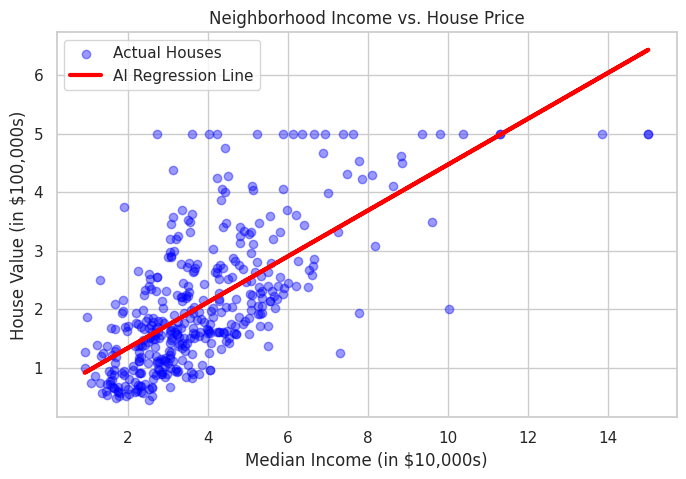

In [258]:
# 1. Split the data into Training (80%) and Testing (20%)
X_train, X_test, y_train, y_test = train_test_split(X_house, y_house, test_size=0.2, random_state=42)

# 2. Create and train the model
house_model = LinearRegression()
house_model.fit(X_train, y_train)

# 3. Visualize the Real Data vs Our Model's Line
plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, color='blue', alpha=0.4, label="Actual Houses")
plt.plot(X_train, house_model.predict(X_train), color='red', linewidth=3, label="AI Regression Line")

plt.title("Neighborhood Income vs. House Price")
plt.xlabel("Median Income (in $10,000s)")
plt.ylabel("House Value (in $100,000s)")
plt.legend()
plt.show()

In [259]:
# Evaluate the model on the Test Set
test_predictions = house_model.predict(X_test)
error = mean_absolute_error(y_test, test_predictions)
print(f"Model Error: On average, our predictions are off by ${error * 100000:,.0f}")

# Predict a brand new neighborhood
new_income = 5.0  # representing $50,000
new_data = pd.DataFrame({"MedInc": [new_income]})

predicted_price = house_model.predict(new_data)[0]

print(f"\n🔮 If a neighborhood's median income is ${new_income * 10000:,.0f},")
print(f"the AI predicts the house will cost: ${predicted_price * 100000:,.0f}")

Model Error: On average, our predictions are off by $63,927

🔮 If a neighborhood's median income is $50,000,
the AI predicts the house will cost: $251,345


In [260]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

In [261]:
# Student dataset
data = {
    "Hours_Studied": [1,2,3,4,5,6,7,8,2,6,7,3],
    "Attendance":    [50,55,60,65,70,80,85,90,40,75,88,58],
    "Result":        [0,0,0,0,1,1,1,1,0,1,1,0]  # 0=Fail, 1=Pass
}

In [262]:
df = pd.DataFrame(data)
df

,Hours_Studied,Attendance,Result
0,1,50,0
1,2,55,0
2,3,60,0
3,4,65,0
4,5,70,1
5,6,80,1
6,7,85,1
7,8,90,1
8,2,40,0
9,6,75,1


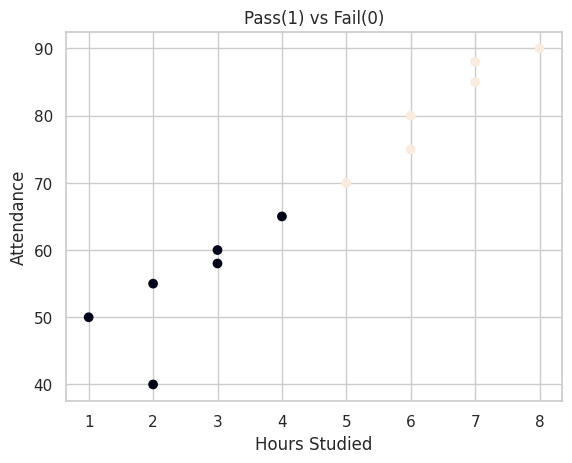

In [263]:
plt.scatter(df["Hours_Studied"], df["Attendance"], c=df["Result"])
plt.xlabel("Hours Studied")
plt.ylabel("Attendance")
plt.title("Pass(1) vs Fail(0)")
plt.show()

In [264]:
X = df[["Hours_Studied", "Attendance"]]
y = df["Result"]

In [265]:
X

,Hours_Studied,Attendance
0,1,50
1,2,55
2,3,60
3,4,65
4,5,70
5,6,80
6,7,85
7,8,90
8,2,40
9,6,75


In [266]:
model = LogisticRegression()
model.fit(X, y)

LogisticRegression()

In [267]:
predictions = model.predict(X)
predictions

array([0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0])

In [268]:
data

{'Hours_Studied': [1, 2, 3, 4, 5, 6, 7, 8, 2, 6, 7, 3],
 'Attendance': [50, 55, 60, 65, 70, 80, 85, 90, 40, 75, 88, 58],
 'Result': [0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0]}

In [269]:
new_student = pd.DataFrame({
    "Hours_Studied":[4],
    "Attendance":[85]
})

model.predict(new_student)

array([1])

In [270]:
print(model.classes_)
model.predict_proba(new_student)

[0 1]


array([[3.39922863e-06, 9.99996601e-01]])

In [271]:
accuracy = accuracy_score(y, predictions)
print("Accuracy:", accuracy)

Accuracy: 1.0


In [272]:
new_student = pd.DataFrame({
    "Hours_Studied":[3],
    "Attendance":[90]
})

model.predict(new_student)

array([1])

In [273]:
cm = confusion_matrix(y, predictions)
print(cm)

[[6 0]
 [0 6]]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


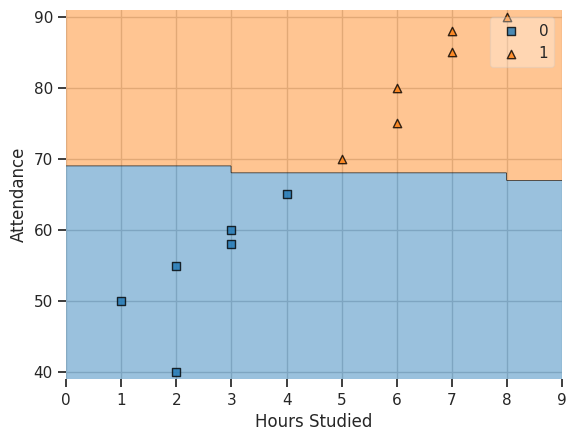

In [274]:
from mlxtend.plotting import plot_decision_regions

plot_decision_regions(X.values, y.values, clf=model)
plt.xlabel("Hours Studied")
plt.ylabel("Attendance")
plt.show()

---
## 🩺 Logistic Regression: Predicting Categories

Linear Regression predicts a *continuous number* (like House Price).
**Logistic Regression** predicts a *category* (0 or 1, Yes or No).

Instead of a straight line, Logistic Regression uses an **S-Curve (Sigmoid)** to squeeze the predictions between 0 (0%) and 1 (100%).

### 🔬 Real-World Project: Breast Cancer Diagnosis
Let's use the famous Breast Cancer dataset. We will give the AI measurements of a tumor (radius, texture, smoothness) and ask it to predict:
* **0 = Benign** (Not dangerous)
* **1 = Malignant** (Dangerous/Cancerous)

In [275]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# 1. Load the Breast Cancer dataset
cancer_data = load_breast_cancer()
X = pd.DataFrame(cancer_data.data, columns=cancer_data.feature_names)
y = cancer_data.target  # 0 = Malignant, 1 = Benign
# (Note: Sklearn defaults Malignant=0, Benign=1. We'll leave it as is!)

print("Here are the tumor features the AI will look at:")
display(X.head(3))

# 2. Split into Training (80%) and Testing (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Here are the tumor features the AI will look at:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758


### ⚖️ The Secret Step: Feature Scaling
The AI looks at 30 different measurements. Some numbers are tiny (`smoothness = 0.05`) and some are massive (`area = 1000.0`).

If we feed this directly into Logistic Regression, the math engine gets confused and crashes (it fails to "converge"). To fix this, we use a **StandardScaler**. It shrinks all the columns down to the exact same scale so the AI can compare them fairly!

In [276]:
from sklearn.preprocessing import StandardScaler

# 1. Initialize the Scaler
scaler = StandardScaler()

# 2. FIT (learn the min/max) and TRANSFORM the Training data
X_train_scaled = scaler.fit_transform(X_train)

# 3. ONLY TRANSFORM the Test data (Never fit on the test data!)
X_test_scaled = scaler.transform(X_test)

# 4. Create the Logistic Regression Model
# (Because the data is scaled, we don't even need max_iter=3000 anymore!)
log_model = LogisticRegression()

# 5. Train the model on the SCALED data
log_model.fit(X_train_scaled, y_train)

print("✅ Logistic Regression Model Trained Successfully (Without Warnings)!")

✅ Logistic Regression Model Trained Successfully (Without Warnings)!


AI Diagnostic Accuracy: 97.37%

--- Detailed Diagnostic Report ---
               precision    recall  f1-score   support

Malignant (0)       0.98      0.95      0.96        43
   Benign (1)       0.97      0.99      0.98        71

     accuracy                           0.97       114
    macro avg       0.97      0.97      0.97       114
 weighted avg       0.97      0.97      0.97       114



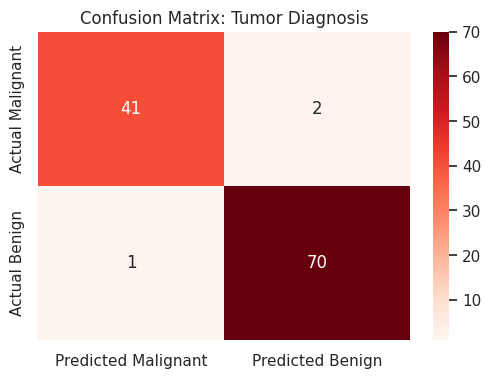

In [277]:
from sklearn.metrics import classification_report

# 1. Make predictions on the SCALED Test set
predictions = log_model.predict(X_test_scaled)

# 2. Check overall Accuracy
acc = accuracy_score(y_test, predictions)
print(f"AI Diagnostic Accuracy: {acc * 100:.2f}%\n")

# 3. Print the detailed Classification Report
print("--- Detailed Diagnostic Report ---")
# Note: In this sklearn dataset, 0 = Malignant, 1 = Benign
print(classification_report(y_test, predictions, target_names=['Malignant (0)', 'Benign (1)']))

# 4. Visualize the Confusion Matrix
cm = confusion_matrix(y_test, predictions)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds',
            xticklabels=['Predicted Malignant', 'Predicted Benign'],
            yticklabels=['Actual Malignant', 'Actual Benign'])
plt.title("Confusion Matrix: Tumor Diagnosis")
plt.show()

### ⚠️ Why is the Confusion Matrix so important here?
In medical AI, **Accuracy is not enough**.
Look at the **False Positives** and **False Negatives**.

* **False Positive (Top-Right):** The AI predicted Benign (Healthy), but the patient actually has a Malignant tumor! (**Extremely Dangerous!**)
* **False Negative (Bottom-Left):** The AI predicted Malignant, but the patient is actually Benign. (Scary for the patient, but doctors will just run more tests).

*Note on Sklearn labels: In this specific dataset, 0 is Malignant and 1 is Benign, which is why our False Positives/Negatives might look visually flipped compared to Class 1. Always check your data labels!*

**As ML Engineers, when building medical AI, our goal is to tune the model so that dangerous mistakes are as close to zero as mathematically possible!**

In [278]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

In [279]:
# Student dataset
data = {
    "Hours_Studied": [1,2,3,4,5,6,7,8,2,6,7,3],
    "Attendance":    [50,55,60,65,70,80,85,90,40,75,88,58],
    "Result":        [0,0,0,0,1,1,1,1,0,1,1,0]  # 0=Fail, 1=Pass
}

In [280]:
df = pd.DataFrame(data)
df

,Hours_Studied,Attendance,Result
0,1,50,0
1,2,55,0
2,3,60,0
3,4,65,0
4,5,70,1
5,6,80,1
6,7,85,1
7,8,90,1
8,2,40,0
9,6,75,1


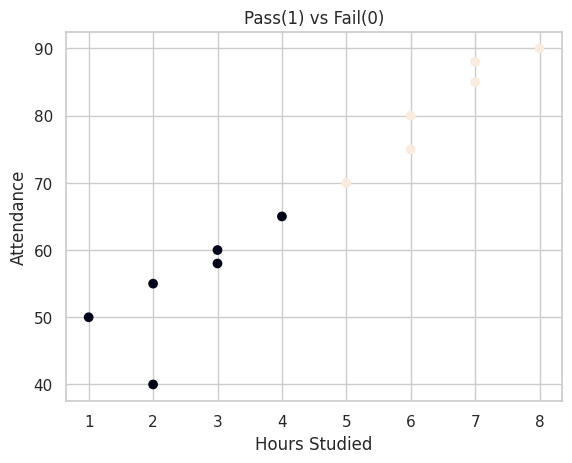

In [281]:
plt.scatter(df["Hours_Studied"], df["Attendance"], c=df["Result"])
plt.xlabel("Hours Studied")
plt.ylabel("Attendance")
plt.title("Pass(1) vs Fail(0)")
plt.show()

In [282]:
X = df[["Hours_Studied", "Attendance"]]
y = df["Result"]

In [283]:
X

,Hours_Studied,Attendance
0,1,50
1,2,55
2,3,60
3,4,65
4,5,70
5,6,80
6,7,85
7,8,90
8,2,40
9,6,75


In [284]:
model = LogisticRegression()
model.fit(X, y)

LogisticRegression()

In [285]:
predictions = model.predict(X)
predictions

array([0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0])

In [286]:
data

{'Hours_Studied': [1, 2, 3, 4, 5, 6, 7, 8, 2, 6, 7, 3],
 'Attendance': [50, 55, 60, 65, 70, 80, 85, 90, 40, 75, 88, 58],
 'Result': [0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0]}

In [287]:
new_student = pd.DataFrame({
    "Hours_Studied":[5],
    "Attendance":[75]
})

model.predict(new_student)

array([1])

In [288]:
print(model.classes_)
model.predict_proba(new_student)

[0 1]


array([[0.00407951, 0.99592049]])

In [289]:
accuracy = accuracy_score(y, predictions)
print("Accuracy:", accuracy)

Accuracy: 1.0


In [290]:
new_student = pd.DataFrame({
    "Hours_Studied":[3],
    "Attendance":[90]
})

model.predict(new_student)

array([1])

In [291]:
cm = confusion_matrix(y, predictions)
print(cm)

[[6 0]
 [0 6]]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


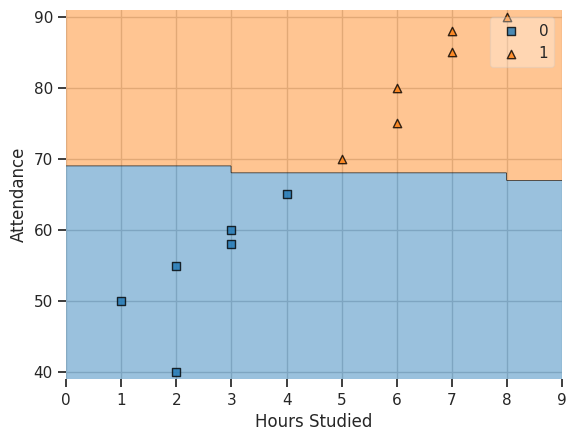

In [292]:
from mlxtend.plotting import plot_decision_regions

plot_decision_regions(X.values, y.values, clf=model)
plt.xlabel("Hours Studied")
plt.ylabel("Attendance")
plt.show()

---
## 🩺 Logistic Regression: Predicting Categories

Linear Regression predicts a *continuous number* (like House Price).
**Logistic Regression** predicts a *category* (0 or 1, Yes or No).

Instead of a straight line, Logistic Regression uses an **S-Curve (Sigmoid)** to squeeze the predictions between 0 (0%) and 1 (100%).

### 🔬 Real-World Project: Breast Cancer Diagnosis
Let's use the famous Breast Cancer dataset. We will give the AI measurements of a tumor (radius, texture, smoothness) and ask it to predict:
* **0 = Benign** (Not dangerous)
* **1 = Malignant** (Dangerous/Cancerous)

In [293]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# 1. Load the Breast Cancer dataset
cancer_data = load_breast_cancer()
X = pd.DataFrame(cancer_data.data, columns=cancer_data.feature_names)
y = cancer_data.target  # 0 = Malignant, 1 = Benign
# (Note: Sklearn defaults Malignant=0, Benign=1. We'll leave it as is!)

print("Here are the tumor features the AI will look at:")
display(X.head(3))

# 2. Split into Training (80%) and Testing (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Here are the tumor features the AI will look at:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758


### ⚖️ The Secret Step: Feature Scaling
The AI looks at 30 different measurements. Some numbers are tiny (`smoothness = 0.05`) and some are massive (`area = 1000.0`).

If we feed this directly into Logistic Regression, the math engine gets confused and crashes (it fails to "converge"). To fix this, we use a **StandardScaler**. It shrinks all the columns down to the exact same scale so the AI can compare them fairly!

In [294]:
from sklearn.preprocessing import StandardScaler

# 1. Initialize the Scaler
scaler = StandardScaler()

# 2. FIT (learn the min/max) and TRANSFORM the Training data
X_train_scaled = scaler.fit_transform(X_train)

# 3. ONLY TRANSFORM the Test data (Never fit on the test data!)
X_test_scaled = scaler.transform(X_test)

# 4. Create the Logistic Regression Model
# (Because the data is scaled, we don't even need max_iter=3000 anymore!)
log_model = LogisticRegression()

# 5. Train the model on the SCALED data
log_model.fit(X_train_scaled, y_train)

print("✅ Logistic Regression Model Trained Successfully (Without Warnings)!")

✅ Logistic Regression Model Trained Successfully (Without Warnings)!


AI Diagnostic Accuracy: 97.37%



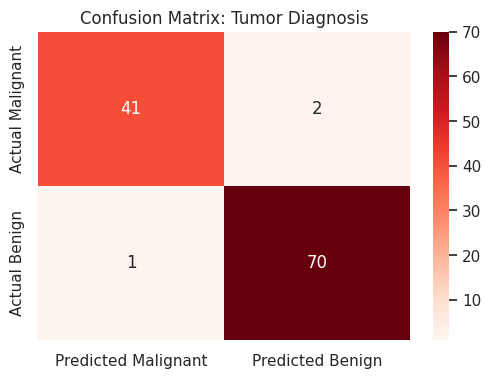

In [295]:
# 5. Make predictions on the SCALED Test set
predictions = log_model.predict(X_test_scaled)

# 6. Check Accuracy
acc = accuracy_score(y_test, predictions)
print(f"AI Diagnostic Accuracy: {acc * 100:.2f}%\n")

# 7. Visualize the Confusion Matrix
cm = confusion_matrix(y_test, predictions)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds',
            xticklabels=['Predicted Malignant', 'Predicted Benign'],
            yticklabels=['Actual Malignant', 'Actual Benign'])
plt.title("Confusion Matrix: Tumor Diagnosis")
plt.show()

---

## 🌉 The Bridge to Deep Learning: What did Logistic Regression just do?

We just trained a **Logistic Regression** model. But how did it actually make its decision mathematically?

Behind the scenes, it did exactly two things:

**1. It calculated a straight line (Weighted Sum):**
It gave a "weight" ($w$) to each feature and added a bias ($b$).

$z = w_1(\text{Hours\_Studied}) + w_2(\text{Attendance}) + b$

**2. It applied the S-Curve (Sigmoid):**
It took that straight line ($z$) and squished it into a probability between 0 and 1 using the Sigmoid function ($\sigma$).

$P(\text{Pass}) = \sigma(z) = \frac{1}{1 + e^{-z}}$

---

Look closely at the math above. In the world of Statistics, we call this **Logistic Regression**.

But in the world of Artificial Intelligence and Deep Learning, if you draw this exact same math equation as a circle with inputs and outputs, it is called a **Single Layer Perceptron (SLP)**!

**Logistic Regression IS a Single Layer Perceptron (with a Sigmoid activation).**
It is the fundamental building block (a single artificial neuron) of a neural network. Let's look at how we build this exact same "brain cell" using Deep Learning code (PyTorch)!


# Single Layer Perceptron (SLP)

A **Single Layer Perceptron** is the simplest form of neural network.  
It takes multiple input features, computes a weighted sum, adds a bias term, and applies an activation function.

In this notebook, we use two important student features:

- **Hours_Studied**
- **Attendance**

to predict whether a student will **Pass (1)** or **Fail (0)**.

---

## Mathematical Representation

For two input features:


$z = w_1(\text{Hours\_Studied}) + w_2(\text{Attendance}) + b$

Output:


$y = \sigma(z)$


where:

- $(w_1, w_2)$ are weights
- $b$ is bias
- $\sigma$ is the sigmoid activation function

---

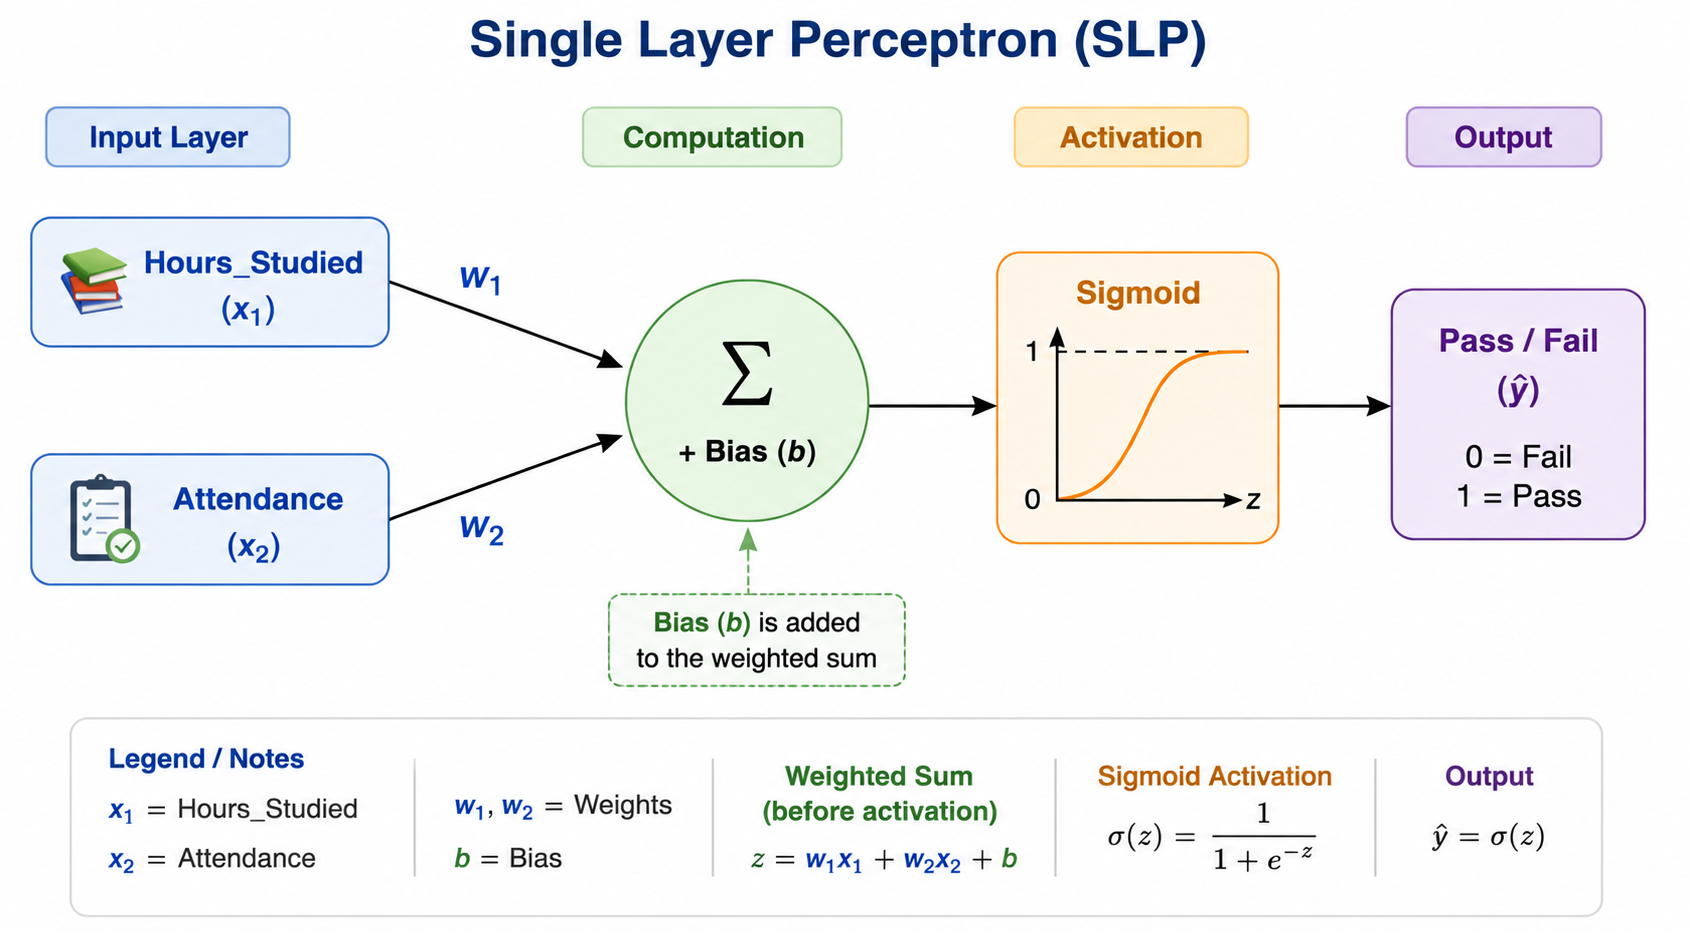
---

## Key Characteristics

- Only one trainable layer
- Works well for linearly separable data
- Fast and simple
- Cannot model highly complex patterns


---
## 🧮 The 4 Math Pillars of Neural Networks
Before we look at the architecture of an Artificial Brain, we need to understand the 4 simple math steps it uses to think and learn. Don't worry, no calculus required!

**1. The Weighted Sum ($\Sigma$)**
The brain takes your inputs ($x$), multiplies them by an importance factor called a weight ($w$), and adds them all together. It also adds a Bias ($b$) to shift the result.
* *Equation: $z = w_1x_1 + w_2x_2 + b$*

**2. The Activation Function ($f$)**
The weighted sum ($z$) can be a massive, crazy number. The Activation Function acts as a filter or "gatekeeper".
* **Sigmoid** squishes the number between 0 and 1 (giving us a probability).
* **ReLU** turns any negative number into a 0, but leaves positive numbers alone.

**3. The Loss Function (The Scoreboard)**
After the network makes a guess, it checks the real answer. The Loss Function measures exactly how wrong the guess was. (High Loss = Bad, Zero Loss = Perfect).

**4. Gradient Descent (How it Learns)**
How does the machine actually get smarter? Imagine a blindfolded hiker trying to find the lowest valley on a mountain. The machine checks the slope of the error, takes a step downhill by adjusting its weights ($w$) slightly, and guesses again. It repeats this thousands of times until it reaches the bottom of the valley (Zero Error)!

---
## 🎛️ The AI Control Panel (Hyperparameters)

When we train an Artificial Neural Network, the machine learns the **Weights and Biases** entirely on its own. However, *we* (the humans) have to configure the settings of the brain before we press start! We call these human settings **Hyperparameters**.

Here are the 3 settings we will control in our code today:

**1. Hidden Layers (`hidden_layer_sizes`)**
How big is the brain? If we set it to `(10, 5)`, we are creating two hidden layers of neurons. A committee of 10 neurons will look at the data, and pass their findings to a second committee of 5 neurons.

**2. Epochs (`max_iter`)**
How many times should the AI study the data? An **Epoch** is one complete read-through of the entire dataset. Just like humans studying for a test, reading the data 1 time isn't enough. We usually set this to 500 or 1000 so the AI has time to memorize the patterns.

**3. Learning Rate (`learning_rate_init`)**
Remember our blindfolded hiker stepping down the mountain to minimize the error? The Learning Rate is the **size of their steps**.
* If the step is too big, the AI jumps completely over the solution!
* If the step is too small, it takes forever to finish training.
* We usually leave this at a small "Goldilocks" number, like `0.001`.
---

In [296]:
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import matplotlib.pyplot as plt

In [297]:
# Student features: Hours_Studied and Attendance

X = torch.tensor([
    [1.0, 50.0],
    [2.0, 55.0],
    [3.0, 60.0],
    [4.0, 65.0],
    [5.0, 70.0],
    [6.0, 80.0],
    [7.0, 85.0],
    [8.0, 90.0]
])

y = torch.tensor([
    [0.0],
    [0.0],
    [0.0],
    [0.0],
    [1.0],
    [1.0],
    [1.0],
    [1.0]
])

In [298]:
# Single Layer Perceptron (SLP)

model = nn.Sequential(
    nn.Linear(2,1),
    nn.Sigmoid()
)

In [299]:
criterion = nn.BCELoss()
optimizer = optim.SGD(model.parameters(), lr=0.1)

In [300]:
for epoch in range(200):
    y_pred = model(X)
    loss = criterion(y_pred, y)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

print("Training complete")

Training complete


In [301]:
test = torch.tensor([[6.0, 78.0]])
prediction = model(test)

print("Pass probability:", prediction.item())

Pass probability: 0.0



# Multi Layer Perceptron (MLP)

A **Multi Layer Perceptron (MLP)** extends the perceptron by adding one or more hidden layers.

This allows the network to learn more complex relationships between:

- **Hours_Studied**
- **Attendance**
- Final Result (Pass/Fail)

---

## Architecture of MLP

An MLP generally contains:

1. Input Layer
2. Hidden Layer(s)
3. Output Layer

---
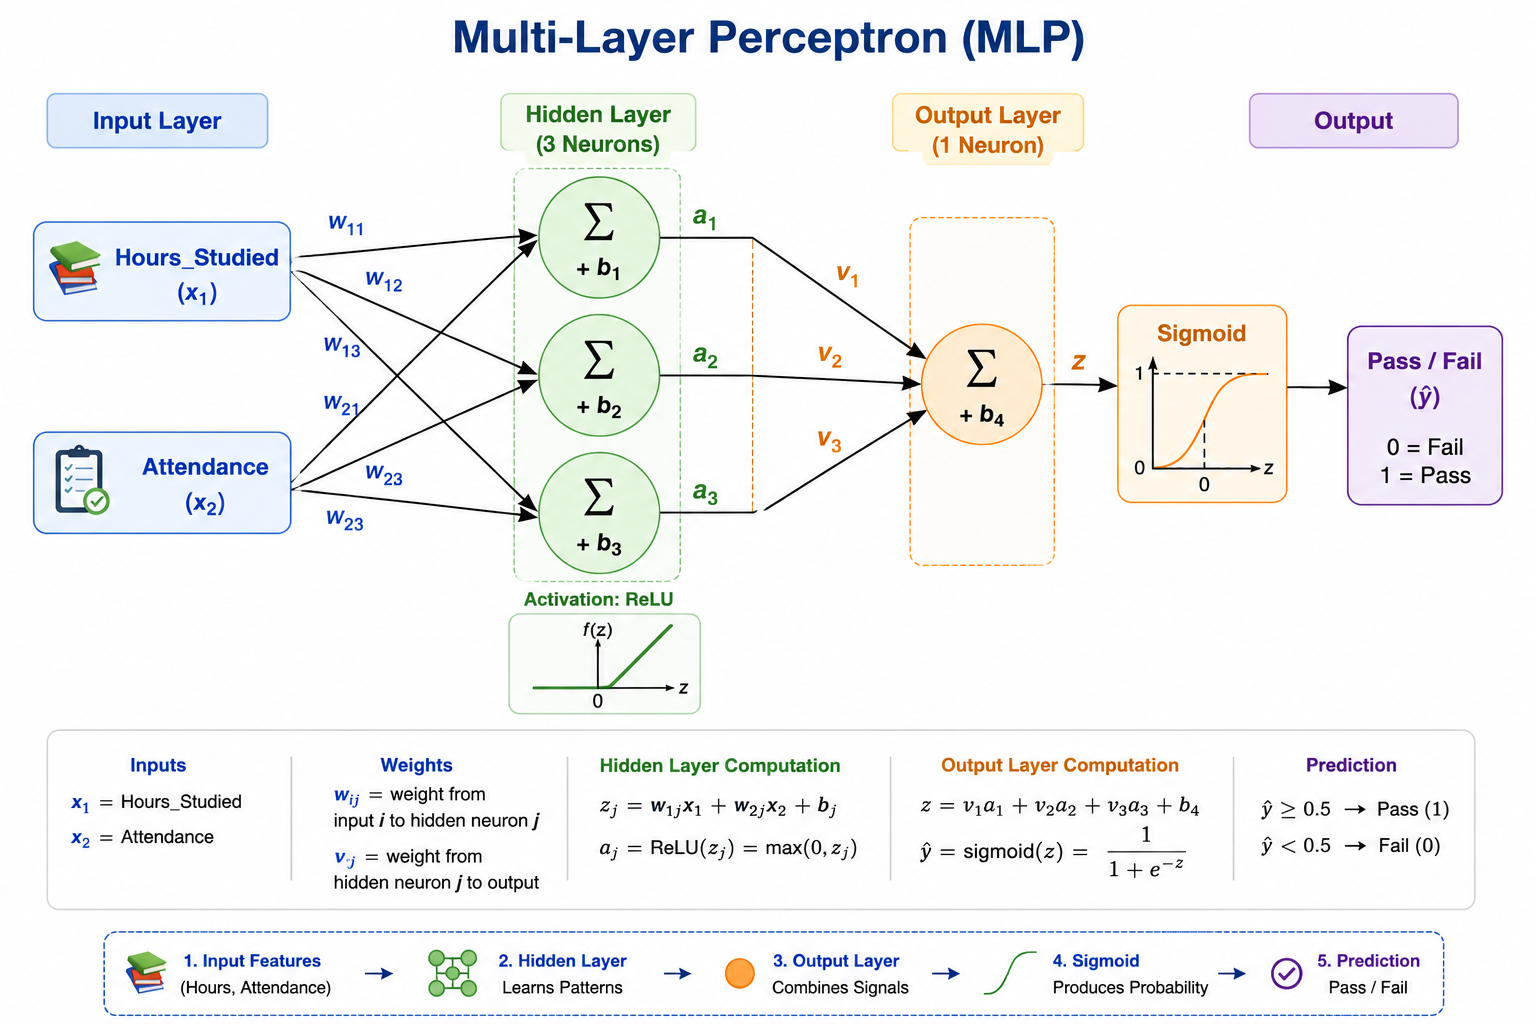

---

## Why MLP is More Powerful

Compared to a Single Layer Perceptron:

- Learns non-linear relationships
- Captures interactions between Hours_Studied and Attendance
- Better generalization capability
- Foundation of Deep Learning

---


## Training Process

1. Forward Propagation
2. Loss Computation
3. Backpropagation
4. Weight Update
5. Repeat for many epochs

---

## Comparison: SLP vs MLP

| Feature | SLP | MLP |
|---|---|---|
| Hidden Layers | No | Yes |
| Complexity | Low | High |
| Non-linear Learning | No | Yes |
| Computational Cost | Low | Higher |
| Real-world Usage | Limited | Very Common |


In [302]:
# Multi Layer Perceptron (MLP)

mlp = nn.Sequential(
    nn.Linear(2,5),
    nn.ReLU(),
    nn.Linear(5,1),
    nn.Sigmoid()
)

In [303]:
test

tensor([[ 6., 78.]])

In [304]:
optimizer = optim.SGD(mlp.parameters(), lr=0.1)

for epoch in range(200):
    y_pred = mlp(X)
    loss = criterion(y_pred, y)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

print("MLP training done")

MLP training done


In [305]:
# 1. Get the probability from the model
prediction = mlp(test)
probability = prediction.item()

print(f"MLP pass probability: {probability * 100:.2f}%")

# 2. Convert the probability to a Class (0 or 1) using a 0.5 threshold
if probability >= 0.5:
    predicted_class = 1
    print("Predicted Class: 1 (PASS) ✅")
else:
    predicted_class = 0
    print("Predicted Class: 0 (FAIL) ❌")

MLP pass probability: 49.94%
Predicted Class: 0 (FAIL) ❌



# Understanding the Decision Boundary

The model learns how both:

- Higher study hours
- Better attendance

increase the probability of passing.

The neural network automatically learns the importance of each feature using weights during training.

For example:

- A student with low study hours but excellent attendance may still pass.
- A student with high study hours but poor attendance may have lower probability.

This demonstrates how neural networks combine multiple features for intelligent prediction.


# 🤖 Unsupervised Learning & Clustering

## Learn by Doing

Today you will learn:
- What is unsupervised learning?
- What is clustering?
- How K-Means clustering works
- How machines group similar data

💡 No labels required!

# 🧠 Supervised vs Unsupervised Learning

## Supervised Learning
- Data has labels
- Example:
    - Pass / Fail
    - Spam / Not Spam

## Unsupervised Learning
- Data has NO labels
- Machine finds hidden patterns

Example:
- Customer groups
- Similar products
- Friend suggestions

In [306]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans

In [307]:
# Simple student dataset

data = {
    "Hours_Studied": [1,2,3,4,5,6,7,8,2,7],
    "Attendance":    [40,45,50,55,65,70,80,90,35,85]
}

df = pd.DataFrame(data)

df

,Hours_Studied,Attendance
0,1,40
1,2,45
2,3,50
3,4,55
4,5,65
5,6,70
6,7,80
7,8,90
8,2,35
9,7,85


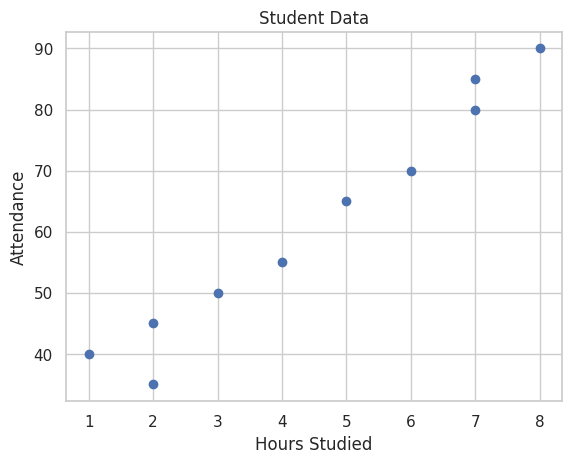

In [308]:
plt.scatter(df["Hours_Studied"], df["Attendance"])

plt.xlabel("Hours Studied")
plt.ylabel("Attendance")

plt.title("Student Data")

plt.show()

# 🎯 Clustering

Clustering means:
👉 Grouping similar data points together.

Goal:
- Similar points → same cluster
- Different points → different clusters

Example:
- Hardworking students
- Average students
- Low-engagement students

In [309]:
# Create K-Means model

kmeans = KMeans(n_clusters=2, random_state=42)

# Train model
kmeans.fit(df)

KMeans(n_clusters=2, random_state=42)

In [310]:
# Cluster assignments

kmeans.labels_

array([0, 0, 0, 0, 1, 1, 1, 1, 0, 1], dtype=int32)

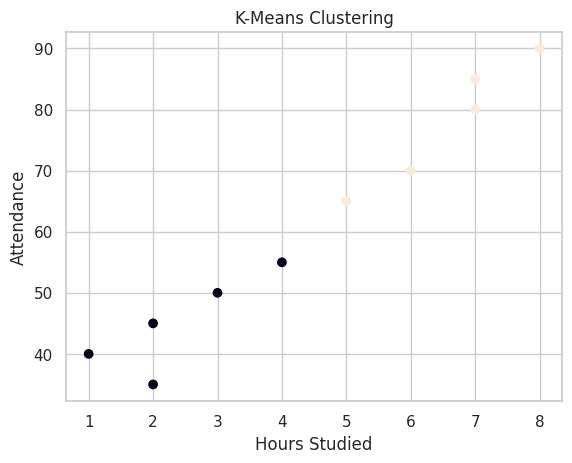

In [311]:
plt.scatter(
    df["Hours_Studied"],
    df["Attendance"],
    c=kmeans.labels_
)

plt.xlabel("Hours Studied")
plt.ylabel("Attendance")

plt.title("K-Means Clustering")

plt.show()

In [312]:
kmeans.cluster_centers_

array([[ 2.4, 45. ],
       [ 6.6, 78. ]])

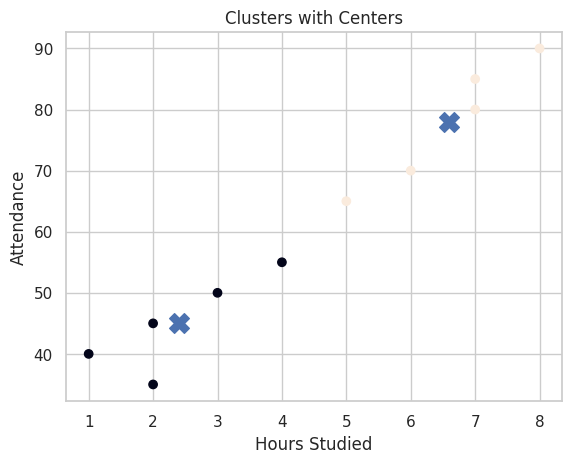

In [313]:
plt.scatter(
    df["Hours_Studied"],
    df["Attendance"],
    c=kmeans.labels_
)

plt.scatter(
    kmeans.cluster_centers_[:,0],
    kmeans.cluster_centers_[:,1],
    s=200,
    marker='X'
)

plt.xlabel("Hours Studied")
plt.ylabel("Attendance")

plt.title("Clusters with Centers")

plt.show()

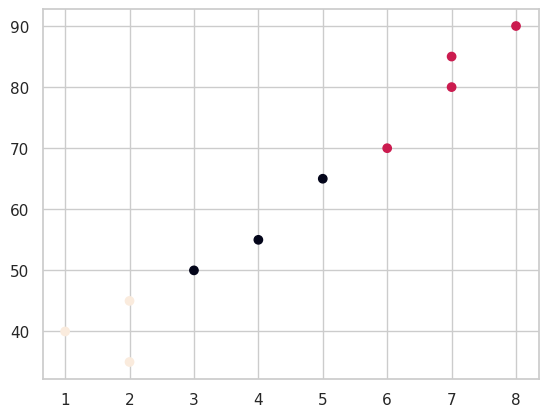

In [314]:
kmeans = KMeans(n_clusters=3, random_state=42)

kmeans.fit(df)

plt.scatter(
    df["Hours_Studied"],
    df["Attendance"],
    c=kmeans.labels_
)

plt.show()

# 🌍 Real-World Applications of Clustering

- Customer segmentation
- Friend recommendations
- Product grouping
- Fraud detection

# 🧪 Mini Activity

Try:
1. Change number of clusters
2. Add new students
3. Observe cluster changes

💡 Experiment like a real ML engineer!

# ✅ What You Learned

- Unsupervised learning uses unlabeled data
- Clustering groups similar data
- K-Means is a clustering algorithm
- Machines can discover hidden patterns

👏 You now know all 3 major ML types:
- Regression
- Classification
- Clustering

In [315]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib import rc

# Display animations in Colab
rc('animation', html='jshtml')

# --------------------------------------------------
# Generate sample data
# --------------------------------------------------

np.random.seed(42)

cluster1 = np.random.randn(100, 2) + [4, 4]
cluster2 = np.random.randn(100, 2) + [6, 5]

X = np.vstack([cluster1, cluster2])

# --------------------------------------------------
# Initial random centroids
# --------------------------------------------------

centroids = np.array([
    [1, 8],
    [8, 2]
])


# Store animation history
history_centroids = []
history_labels = []
history_titles = []

# Initial state (before clustering)
history_centroids.append(centroids.copy())
history_labels.append(None)
history_titles.append("Initial Random Centroids")

# --------------------------------------------------
# K-Means iterations
# --------------------------------------------------

for iteration in range(5):

    # Step 1: Assign points to nearest centroid
    distances = []

    # Calculate distance from every point to every centroid
    for point in X:

        point_distances = []

        for centroid in centroids:

            distance = np.linalg.norm(point - centroid)

            point_distances.append(distance)

        distances.append(point_distances)

    distances = np.array(distances)


    labels = np.argmin(distances, axis=1)

    history_centroids.append(centroids.copy())
    history_labels.append(labels.copy())
    history_titles.append(
        f"Iteration {iteration + 1}: Assign Points"
    )

    # Step 2: Move centroids
    new_centroids = np.array([
        X[labels == i].mean(axis=0)
        for i in range(len(centroids))
    ])

    history_centroids.append(new_centroids.copy())
    history_labels.append(labels.copy())
    history_titles.append(
        f"Iteration {iteration + 1}: Move Centroids"
    )

    centroids = new_centroids

# --------------------------------------------------
# Animation
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(6, 6))

def update(frame):

    ax.clear()

    labels = history_labels[frame]
    centers = history_centroids[frame]

    # Initial frame
    if labels is None:
        ax.scatter(
            X[:, 0],
            X[:, 1],
            color='gray',
            s=60
        )
    else:
        ax.scatter(
            X[:, 0],
            X[:, 1],
            c=labels,
            s=60
        )

    ax.scatter(
        centers[:, 0],
        centers[:, 1],
        marker='X',
        s=300,
        c='red'
    )

    ax.set_xlim(0, 11)
    ax.set_ylim(0, 11)

    ax.set_title(history_titles[frame])

ani = FuncAnimation(
    fig,
    update,
    frames=len(history_centroids),
    interval=1500,
    repeat=False
)

# Prevent static figure from appearing
plt.close(fig)

ani

In [316]:
ani.save(
    "kmeans_animation.gif",
    writer="pillow",
    fps=1
)

# 🔍 Beyond K-Means

K-Means is popular, but not the only clustering algorithm.

Two other important methods are:

1. DBSCAN
2. Hierarchical Clustering

# 🌌 DBSCAN Clustering

DBSCAN groups:
👉 Dense nearby points together

It can:
✅ Find irregular cluster shapes
✅ Detect outliers/noise

Unlike K-Means:
❌ No need to specify number of clusters

In [317]:
from sklearn.cluster import DBSCAN

In [318]:
df = pd.DataFrame({
    "Hours_Studied": [
        2,3,2,3,4,          # Cluster 1
        10,11,10,12,11,     # Cluster 2
        18                  # Noise
    ],

    "Attendance": [
        60,62,58,61,63,
        85,87,84,88,86,
        40
    ]
})

print(df)

    Hours_Studied  Attendance
0               2          60
1               3          62
2               2          58
3               3          61
4               4          63
5              10          85
6              11          87
7              10          84
8              12          88
9              11          86
10             18          40


In [319]:
X = df[["Hours_Studied", "Attendance"]]

dbscan = DBSCAN(
    eps=4,
    min_samples=2
)

labels = dbscan.fit_predict(X)

print(labels)

[ 0  0  0  0  0  1  1  1  1  1 -1]


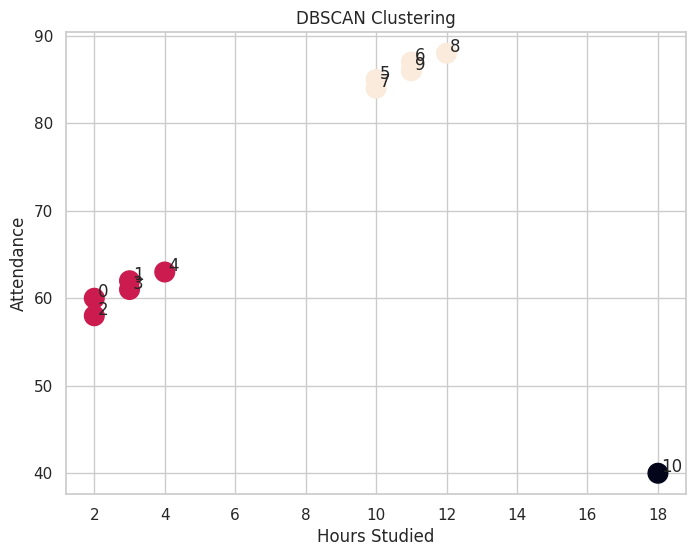

In [320]:
plt.figure(figsize=(8,6))

plt.scatter(
    df["Hours_Studied"],
    df["Attendance"],
    c=labels,
    s=200
)

for i,row in df.iterrows():
    plt.text(
        row["Hours_Studied"]+0.1,
        row["Attendance"]+0.1,
        str(i)
    )

plt.xlabel("Hours Studied")
plt.ylabel("Attendance")

plt.title("DBSCAN Clustering")

plt.show()

In [321]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.patches import Circle

fig, ax = plt.subplots(figsize=(8,6))

eps = 4

def update(frame):

    ax.clear()

    ax.scatter(
        df["Hours_Studied"],
        df["Attendance"],
        s=120
    )

    point = X.iloc[frame]

    circle = Circle(
        (point["Hours_Studied"],
         point["Attendance"]),
        eps,
        fill=False,
        linewidth=2
    )

    ax.add_patch(circle)

    ax.scatter(
        point["Hours_Studied"],
        point["Attendance"],
        s=300
    )

    ax.set_title(
        f"Checking Point {frame}"
    )

ani = FuncAnimation(
    fig,
    update,
    frames=len(df),
    interval=1200
)

# Prevent static figure from appearing
plt.close(fig)

ani

# 🧠 K-Means vs DBSCAN

## K-Means
- Needs number of clusters

## DBSCAN
- Finds dense regions
- Can detect noise/outliers
- Handles irregular shapes